In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

/home/vansh-talyani/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
I0000 00:00:1793565800.366553  226893 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793565800.720386  226893 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793565803.477538  226893 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
df = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/AutoEncoder/CreditCard/creditcard.csv")

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [42]:
X=df.drop('Class',axis=1)
y=df['Class']
X

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00


In [43]:
X = pd.get_dummies(X)
X

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00


In [14]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=42)

In [15]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [16]:
X_normal = X_train[y_train==0]

In [45]:
autoencoder = Sequential()

autoencoder.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
autoencoder.add(Dense(X_train.shape[1], activation='linear'))

In [21]:
autoencoder.compile(optimizer='adam',loss='mean_squared_error')

In [29]:
r=autoencoder.fit(X_normal,X_normal,epochs = 11,batch_size=128,validation_data=(X_test,X_test))

Epoch 1/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 3.5546e-04 - val_loss: 0.0017
Epoch 2/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 3.8548e-04 - val_loss: 0.0020
Epoch 3/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 3.7251e-04 - val_loss: 0.0026
Epoch 4/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 4.1058e-04 - val_loss: 0.0044
Epoch 5/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 2.6215e-04 - val_loss: 8.3126e-04
Epoch 6/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 2.2458e-04 - val_loss: 9.5918e-04
Epoch 7/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 4.8700e-04 - val_loss: 8.5138e-04
Epoch 8/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.6473e-04 - val_loss: 9.1364e-04
Epoch 9/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 3.7218e-04 - val_loss: 8.5531e-04
Epoch 10/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 5.9151e-04 - val_loss: 8.0849e-04
Epoch 11/11
1555/1555 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step 

In [30]:
loss=autoencoder.evaluate(X_test,X_test)
print(loss)

2671/2671 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - loss: 0.0015
0.001462375046685338


In [84]:
predicted = autoencoder.predict(X_test)

mse = np.mean(np.square(X_test-predicted),axis=1)

2671/2671 ━━━━━━━━━━━━━━━━━━━━ 1s 372us/step


In [85]:
normal_predicted = autoencoder.predict(X_normal)
normal_mse = np.mean(np.square(X_normal - normal_predicted), axis=1)
threshold = np.percentile(normal_mse, 95)

6219/6219 ━━━━━━━━━━━━━━━━━━━━ 2s 358us/step


In [86]:
outliers = (mse > threshold).astype(int)

In [87]:
print(confusion_matrix(y_test,outliers))
print(classification_report(y_test,outliers))

[[81033  4274]
 [   13   123]]
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     85307
           1       0.03      0.90      0.05       136

    accuracy                           0.95     85443
   macro avg       0.51      0.93      0.51     85443
weighted avg       1.00      0.95      0.97     85443



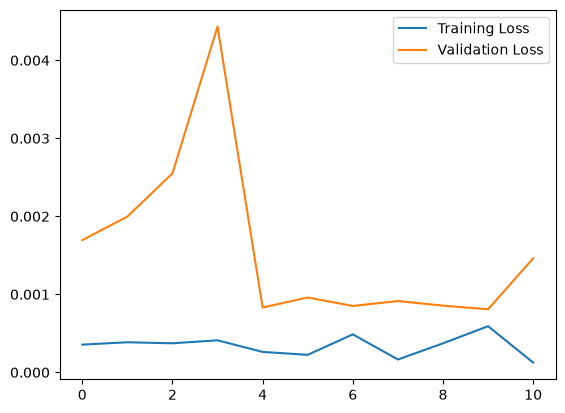

In [88]:
plt.plot(r.history['loss'])
plt.plot(r.history['val_loss'])
plt.legend(['Training Loss', 'Validation Loss'])
plt.show()